# 03 · Baseline forecasts

Every learning model in later phases must beat these baselines. Each one is re-estimated at the start of every month from January 2012, using only data available then, and forecasts the next trading day for every day of that month (`scripts/run_baselines.py`).

- **Volatility**: the naive forecast (tomorrow = today's realized variance), RiskMetrics EWMA, GARCH(1,1), GJR-GARCH (both Student-t, fitted by maximum likelihood) and HAR-RV.
- **Returns**: zero (the random walk), the historical mean and an ARMA model with orders chosen by AIC each year.
- **Direction**: the historical share of up days, and persistence (tomorrow moves the way today did).

Significance: Diebold–Mariano tests compare each model's daily losses with the reference (naive, zero and frequency respectively); a negative statistic means lower loss. Pesaran–Timmermann tests whether up/down calls beat chance.

In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from fxml.config import load_config
from fxml import viz
from fxml.validation.metrics import qlike_losses

cfg = load_config()
viz.apply_style()
tables = cfg.paths.reports / "tables"
vol = pd.read_csv(tables / "baselines_volatility.csv")
ret = pd.read_csv(tables / "baselines_returns.csv")
direction = pd.read_csv(tables / "baselines_direction.csv")
predictions = pd.read_parquet(cfg.paths.reports / "predictions" / "baselines.parquet")
pairs = list(cfg.pairs)
pd.set_option("display.precision", 4)

## Volatility

Average over the seven pairs (QLIKE and log errors: lower is better).

In [2]:
cols = ["qlike", "rmse_log", "mae_log", "mz_r2", "mz_slope"]
vol[vol.pair == "average"].set_index("model")[cols].sort_values("qlike")

,qlike,rmse_log,mae_log,mz_r2,mz_slope
model,,,,,
har,0.1566,0.4968,0.3826,0.5456,0.9346
garch,0.1931,0.5545,0.4278,0.4420,0.9417
gjr_garch,0.1973,0.5571,0.4285,0.4367,0.9349
naive,0.2117,0.5679,0.4228,0.4609,0.6785
ewma,0.2131,0.5497,0.4160,0.4489,0.7887


In [3]:
vol[vol.pair != "average"].pivot(index="pair", columns="model", values="qlike").loc[pairs]

model,ewma,garch,gjr_garch,har,naive
pair,,,,,
EURUSD,0.1724,0.1636,0.1653,0.1403,0.2049
GBPUSD,0.1833,0.1736,0.1778,0.1395,0.1804
USDJPY,0.2684,0.2617,0.2664,0.2263,0.3192
USDCHF,0.3473,0.2999,0.3241,0.2236,0.2504
AUDUSD,0.1784,0.1567,0.1555,0.1244,0.1723
USDCAD,0.1628,0.1429,0.1398,0.1202,0.1811
NZDUSD,0.1792,0.1530,0.1525,0.1219,0.1739


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


PosixPath('./reports/figures/baselines_volatility_gain.png')

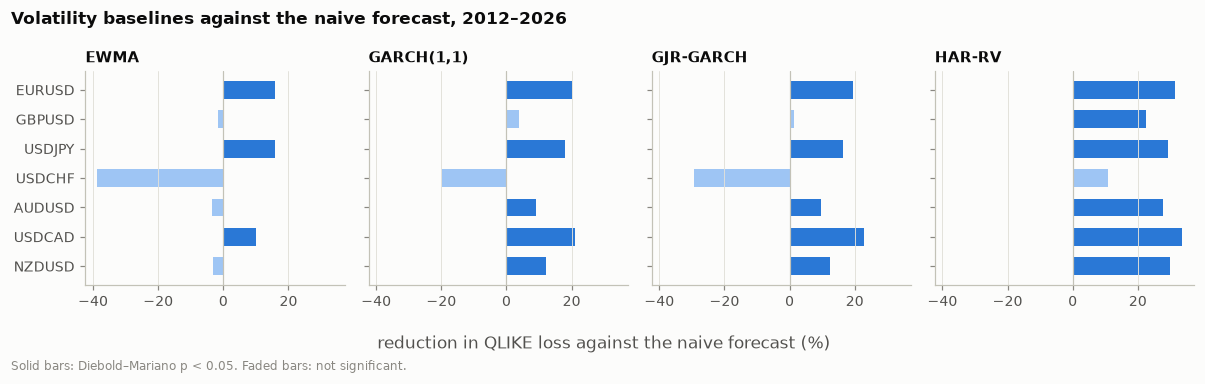

In [4]:
models = ["ewma", "garch", "gjr_garch", "har"]
names = {"ewma": "EWMA", "garch": "GARCH(1,1)", "gjr_garch": "GJR-GARCH", "har": "HAR-RV"}
per_pair = vol[vol.pair != "average"].set_index(["model", "pair"])
naive = per_pair.loc["naive", "qlike"]

fig, axes = plt.subplots(1, 4, figsize=(11, 3.2), sharex=True, sharey=True)
for ax, model in zip(axes, models):
    gain = 100 * (1 - per_pair.loc[model, "qlike"] / naive).loc[pairs]
    significant = (per_pair.loc[model, "dm_p_vs_naive"].loc[pairs] < 0.05).to_numpy()
    colors = [viz.CATEGORICAL[0] if s else viz.SEQUENTIAL_BLUE[1] for s in significant]
    ax.barh(pairs, gain, color=colors, height=0.6)
    ax.axvline(0, color=viz.BASELINE, lw=0.8)
    ax.set_title(names[model])
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.supxlabel("reduction in QLIKE loss against the naive forecast (%)", color=viz.INK_SECONDARY)
fig.suptitle("Volatility baselines against the naive forecast, 2012–2026", x=0.01, ha="left",
             fontweight="semibold")
fig.text(0.01, -0.04, "Solid bars: Diebold–Mariano p < 0.05. Faded bars: not significant.",
         color=viz.INK_MUTED, fontsize=8)
fig.tight_layout()
viz.save(fig, "baselines_volatility_gain")

USD/CHF is the one pair where no model clearly beats the naive forecast. The 15 January 2015 franc shock dominates its losses, so here is the same comparison without the month that followed it.

In [5]:
chf = predictions[(predictions.task == "volatility") & (predictions.pair == "USDCHF")]
shock = (chf.date >= "2015-01-14") & (chf.date <= "2015-02-13")
def mean_qlike(frame):
    return frame.groupby("model").apply(lambda g: qlike_losses(g.actual, g.forecast).mean())
pd.DataFrame({"all days": mean_qlike(chf), "without 14 Jan - 13 Feb 2015": mean_qlike(chf[~shock])})

,all days,without 14 Jan - 13 Feb 2015
model,,
ewma,0.3473,0.1765
garch,0.2999,0.1509
gjr_garch,0.3241,0.1551
har,0.2236,0.1221
naive,0.2504,0.1740


PosixPath('./reports/figures/baselines_volatility_rolling_eurusd.png')

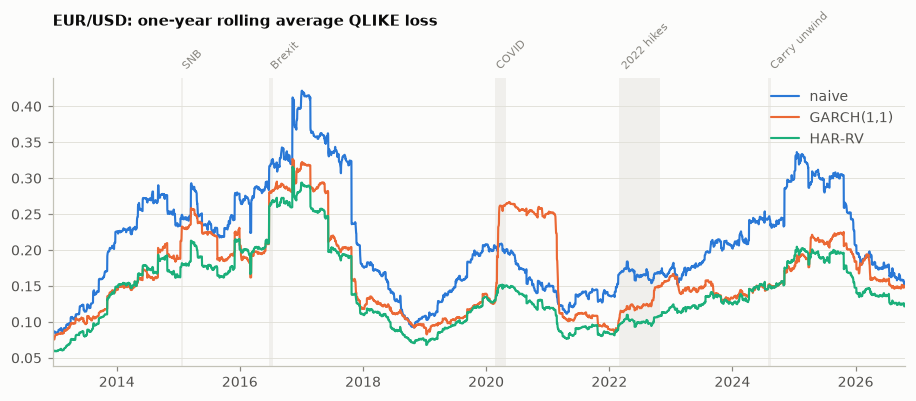

In [6]:
# Rolling one-year average QLIKE loss for EUR/USD: losses rise in every stress period
eur = predictions[(predictions.task == "volatility") & (predictions.pair == "EURUSD")]
wide = eur.pivot(index="date", columns="model", values="forecast")
actual = eur.drop_duplicates("date").set_index("date")["actual"].reindex(wide.index)
show = {"naive": "naive", "garch": "GARCH(1,1)", "har": "HAR-RV"}
fig, ax = plt.subplots(figsize=(10, 3.4))
viz.shade_stress(ax, label=True, since=wide.index[250])
for i, (model, label) in enumerate(show.items()):
    rolling = pd.Series(qlike_losses(actual, wide[model]), index=wide.index).rolling(250).mean()
    ax.plot(rolling.index, rolling, color=viz.CATEGORICAL[i], label=label)
ax.set_xlim(wide.index[250], wide.index[-1])
ax.legend(loc="upper right")
ax.set_title("EUR/USD: one-year rolling average QLIKE loss", pad=34)
viz.save(fig, "baselines_volatility_rolling_eurusd")

## Returns

`r2_oos` compares squared errors with always forecasting zero; negative means worse than zero.

In [7]:
ret[ret.pair == "average"].set_index("model")[["rmse", "mae", "r2_oos", "sign_hit_rate"]]

,rmse,mae,r2_oos,sign_hit_rate
model,,,,
arima,0.0056,0.004,-0.0027,0.5028
mean,0.0055,0.004,-0.0005,0.4966
zero,0.0055,0.004,0.0000,NaN


In [8]:
ret[ret.pair != "average"].pivot(index="pair", columns="model", values="r2_oos").loc[pairs]

model,arima,mean,zero
pair,,,
EURUSD,-0.0017,-0.0003,0.0
GBPUSD,-0.0012,-0.0002,0.0
USDJPY,-0.0044,-0.0011,0.0
USDCHF,-0.0037,-0.0004,0.0
AUDUSD,-0.0028,-0.0008,0.0
USDCAD,-0.0013,-0.0004,0.0
NZDUSD,-0.0042,-0.0004,0.0


## Direction

In [9]:
cols = ["accuracy", "balanced_accuracy", "roc_auc", "brier", "pt_p"]
direction[direction.pair != "average"].pivot(index="pair", columns="model", values="accuracy").loc[pairs]

model,frequency,persistence
pair,,
EURUSD,0.4913,0.4954
GBPUSD,0.4877,0.5055
USDJPY,0.5081,0.4880
USDCHF,0.5090,0.4892
AUDUSD,0.5012,0.4793
USDCAD,0.4993,0.4813
NZDUSD,0.4962,0.4824


In [10]:
direction[direction.pair == "average"].set_index("model")[[c for c in cols if c in direction]]

,accuracy,balanced_accuracy,roc_auc,brier,pt_p
model,,,,,
frequency,0.4990,0.4996,0.4901,0.2502,NaN
persistence,0.4887,0.4882,0.4882,0.5111,NaN


## Findings

**Volatility is predictable, and HAR-RV is the benchmark to beat.**
- **HAR-RV** cuts QLIKE loss by 26% on average compared with the naive forecast, significantly (Diebold–Mariano p < 0.001) in six of the seven pairs. It also has the best Mincer–Zarnowitz fit (R² 0.55, slope 0.93).
- **GARCH and GJR-GARCH** improve on naive by about 9%, significantly in five pairs. They are clearly weaker than HAR-RV, because they see only daily returns while HAR-RV uses intraday realized variance.
- **EWMA** is no better than naive on average.
- **The naive forecast is badly over-dispersed** (Mincer–Zarnowitz slope 0.68). Today's realized variance is a noisy guide to tomorrow's, so smoothing pays.
- **USD/CHF is the exception, because of one month.** With 14 January – 13 February 2015 excluded, HAR-RV beats naive by 30% there too, like every other pair. Results for USD/CHF should be reported both ways.
- **GARCH can overreact to a shock.** In the year after March 2020 its EUR/USD loss rose well above even the naive forecast, while HAR-RV stayed steady.

**Returns are not predictable by these baselines.** The historical mean and ARMA both do slightly worse than forecasting zero (out-of-sample R² −0.05% and −0.27%), and neither is significantly different from zero in any pair. Their sign calls are right about half the time.

**Direction calls are at chance.** Both baselines are right 49–51% of the time in every pair. Only one of fourteen Pesaran–Timmermann tests is significant at 5%, about what chance alone produces.

**Targets for the learning models (Phase 4):**
- volatility: beat HAR-RV's QLIKE of 0.157 on average;
- returns: any positive out-of-sample R² against zero;
- direction: accuracy reliably above 50% with significant Pesaran–Timmermann tests.
